In [200]:
import pandas as pd 
import numpy as np 
import MetaTrader5 as mt5
from datetime import datetime, timezone
from pathlib import Path

# Pipeline configurations

In [201]:
# Assets configuration

assets = ['EURUSDm','USDCADm','USDJPYm','GBPUSDm','USDCHFm','EURCADm',
          'EURCHFm','EURGBPm','EURJPYm','UKOILm','USOILm','XAUUSDm', 'XAGUSDm']

In [202]:
# Candle timeframe

timeframe = mt5.TIMEFRAME_D1

In [203]:
# Defining initial date to get data

initial_date = datetime(2010, 1, 1, tzinfo=timezone.utc)

# Defining final date to finishing proccess

final_date = datetime.now(timezone.utc)

In [204]:
# Storage and get data function

def data_storage(asset):
    
    # Search for candles on timeframe defined

    rates = mt5.copy_rates_range(asset,
                                 timeframe,
                                 initial_date,
                                 final_date)
    
    # If have a error, break the proccess

    if rates is None or len(rates) == 0:
        print(f'Fail to get data asset {asset}: {mt5.last_error()}')
        return None
    
    # Convert get data in dataframe

    df = pd.DataFrame(rates)

    # Convert the timestamps Unix to datetime with timezone UTC

    df['time'] = pd.to_datetime(df['time'], unit='s', utc=True)

    # Order olders candles to new candles

    df = df.sort_values('time')

    # Remove evenctually register with duplicate timestamp

    df = df.drop_duplicates(subset='time', keep='last')

    # Verify if essential values have a data

    essential_colums = ['time','open','high','low',
                        'close']
    
    if df[essential_colums].isna().any().any():
        raise ValueError(f'{asset}: there is NaN values presents on dataframe')
    
    # Verify if asset price are positive

    if (df[['open','high','low','close']] <= 0).any().any():
        raise ValueError(f'{asset}: there is negative price on dataframe')
    
    # Remove last candle, because most be in close processing

    if not df.empty:
        df = df.iloc[:-1].copy()

    # Adds the asset name to identify the origin of data

    df['symbol'] = asset 

    # Return validated dataframe

    return df

# Create a pipeline to extract Macro indicators

In [ ]:
# Read macro indicators of Euro zone, USA, Canada, Switzerland, England and Japan central banks

canada = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\canada_macro.csv',
                     sep=',', encoding='utf8')
df = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\euro_macro.csv',
                        sep=',', encoding='utf8')
japan = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\japan_macro.csv',
                    sep=',', encoding='utf8')
switz = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\switzerland_macro.csv',
                    sep=',', encoding='utf8')
england = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\uk_macro.csv',
                    sep=',', encoding='utf8')
usa = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\usa_macro.csv',
                    sep=',', encoding='utf8')

In [206]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,NaN,NaN
1,1990-02-01,5.464481,NaN,NaN
2,1990-03-01,5.298913,NaN,0.961690
3,1990-04-01,5.013550,NaN,NaN
4,1990-05-01,4.423592,NaN,NaN
...,...,...,...,...
436,2026-05-01,3.225806,2.25,NaN
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,NaN
439,2026-08-01,3.033981,2.25,NaN


In [ ]:
df

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,NaN,NaN,NaN
1,1990-02-01,NaN,NaN,NaN
2,1990-03-01,NaN,NaN,NaN
3,1990-04-01,NaN,NaN,NaN
4,1990-05-01,NaN,NaN,NaN
...,...,...,...,...
436,2026-05-01,3.171269,2.15,NaN
437,2026-06-01,2.752843,2.40,0.632995
438,2026-07-01,2.941470,2.40,NaN
439,2026-08-01,3.246042,2.40,NaN


In [208]:
japan

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,3.280840,4.25,NaN
1,1990-02-01,3.820817,4.25,NaN
2,1990-03-01,3.669724,5.25,NaN
3,1990-04-01,2.574002,5.25,NaN
4,1990-05-01,2.560820,5.25,NaN
...,...,...,...,...
436,2026-05-01,1.500000,0.75,NaN
437,2026-06-01,1.701701,1.00,0.360456
438,2026-07-01,1.898101,1.00,NaN
439,2026-08-01,NaN,1.00,NaN


In [209]:
switz

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,NaN,NaN,NaN
1,1990-02-01,NaN,NaN,NaN
2,1990-03-01,NaN,NaN,NaN
3,1990-04-01,NaN,NaN,NaN
4,1990-05-01,NaN,NaN,NaN
...,...,...,...,...
436,2026-05-01,0.879648,0.0,NaN
437,2026-06-01,0.727962,0.0,1.884751
438,2026-07-01,0.675810,0.0,NaN
439,2026-08-01,0.915332,0.0,NaN


In [210]:
england

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.511811,14.875,NaN
1,1990-02-01,5.882353,14.875,NaN
2,1990-03-01,5.859375,14.875,0.514596
3,1990-04-01,6.358382,14.875,NaN
4,1990-05-01,6.704981,14.875,NaN
...,...,...,...,...
436,2026-05-01,2.890173,3.750,NaN
437,2026-06-01,2.591793,3.750,0.532607
438,2026-07-01,2.805755,3.750,NaN
439,2026-08-01,3.086863,3.750,NaN


In [211]:
usa 

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.202312,8.25,NaN
1,1990-02-01,5.263158,8.25,NaN
2,1990-03-01,5.233034,8.25,1.092882
3,1990-04-01,4.711617,8.25,NaN
4,1990-05-01,4.361874,8.25,NaN
...,...,...,...,...
436,2026-05-01,4.248674,3.75,NaN
437,2026-06-01,3.531425,3.75,0.550490
438,2026-07-01,3.364825,3.75,NaN
439,2026-08-01,3.396548,3.75,NaN


# Data frame processing and data preparation for macroeconomic analysis.

In [212]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,NaN,NaN
1,1990-02-01,5.464481,NaN,NaN
2,1990-03-01,5.298913,NaN,0.961690
3,1990-04-01,5.013550,NaN,NaN
4,1990-05-01,4.423592,NaN,NaN
...,...,...,...,...
436,2026-05-01,3.225806,2.25,NaN
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,NaN
439,2026-08-01,3.033981,2.25,NaN


In [213]:
"""
    Here, replacing the data with the median is neither the best nor the recommended approach, 
    but since extracting macroeconomic data generally requires an API key from reliable paid sites like Bloomberg,
    And at the moment I don't have such resources for a portfolio project, 
    I decided to extract the data directly from the official central bank websites of each country in question 
    and replace it with the median values ​​to simplify the project 
    and prepare the model for financial market analysis and forecasting, more specifically, the forex market.
"""

def prepare_df_macro(df):
    
    # Copy df

    df = df.copy()

    # Replacing NaN values ​​with the median

    for i in df.columns:
        if i == 'reference_date':
            continue

        df[i] = df[i].fillna(df[i].median())

    # Return df

    return df

In [214]:
canada.isna().sum()

reference_date           0
inflation_yoy            1
central_bank_rate      231
real_gdp_growth_qoq    295
dtype: int64

In [215]:
canada = prepare_df_macro(canada)

In [216]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,1.00,0.636564
1,1990-02-01,5.464481,1.00,0.636564
2,1990-03-01,5.298913,1.00,0.961690
3,1990-04-01,5.013550,1.00,0.636564
4,1990-05-01,4.423592,1.00,0.636564
...,...,...,...,...
436,2026-05-01,3.225806,2.25,0.636564
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,0.636564
439,2026-08-01,3.033981,2.25,0.636564


In [217]:
canada.isna().sum()

reference_date         0
inflation_yoy          0
central_bank_rate      0
real_gdp_growth_qoq    0
dtype: int64

In [ ]:
df = prepare_df_macro(df)
japan = prepare_df_macro(japan)
switz = prepare_df_macro(switz)
england = prepare_df_macro(england)
usa = prepare_df_macro(usa)

# A very important observation here:

In a real investment environment, for data that is not obtained and comes in NaN format, the best approach would be to exclude the NaN rows or seek another data source.

However, as I mentioned, in this market, the best data sources are paid, and for a portfolio project where I handle everything from the initial pipeline process, data extraction, and preparation, there is no need to invest financially in such a project or prepare a mega-structure for something that I may not even execute in the financial market investing real money; it's just study and learning.

But I'm just justifying the practice I adopted of replacing NaN values ​​with the median to facilitate the development of econometric models, because the problem with consulting central bank APIs is that many series are discontinued, many data points are not filled in correctly, generating gaps, etc.

The best way to decide between filling in with the mean, median, or deleting those NaN rows depends on your business rules and how sensitive your model will be to the data.

In [219]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,1.00,0.636564
1,1990-02-01,5.464481,1.00,0.636564
2,1990-03-01,5.298913,1.00,0.961690
3,1990-04-01,5.013550,1.00,0.636564
4,1990-05-01,4.423592,1.00,0.636564
...,...,...,...,...
436,2026-05-01,3.225806,2.25,0.636564
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,0.636564
439,2026-08-01,3.033981,2.25,0.636564


# Returning to extracting data from the financial market with MT5

In [220]:
# Executing pipeline MT5

def main():

    # Initialize MetaTrader5 terminal connection

    if not mt5.initialize():
        raise RuntimeError(
            f'Not possible connect to MT5: {mt5.last_error()}'
        )
    
    try:

        # Show informations terminal connected

        terminal = mt5.terminal_info()
        print('MetaTrader5 connected!')
        print(f'Connected terminal: {terminal is not None}')

        # Storage the dataframe colected

        dataframes = {}

        # It goes through all connected assets

        for asset in assets:
            print(f'Extracting data to {asset}')

            # Guarantees if selected asset be on terminal

            if not mt5.symbol_select(asset, True):
                print(f'Asset currently unavailable: {asset}')
                continue

            try: 

                # Executing strorage and mkae a dataframe

                df = data_storage(asset)

                # Ignore the asset if the collection did not return any data.

                if df is None or df.empty:
                    print(f'No close candle available: {asset}')
                    continue 

                # Save dataframe

                globals()[asset] = df

                # Show summary of storage

                print(f'Rows storaged: {len(df)}')
                print(f"First candle: {df['time'].min()}")
                print(f"Last candle {df['time'].max()}")
                

            except Exception as erro:

                # Fail register and keep goin with another assets

                print(f'Error to proccess {asset}: {erro}')

        # Show how many assets are processed

        print(f'Pipeline finish. Assets processed: {len(dataframes)}')

        # Return df

        return dataframes

    finally:

        # Closing MetaTrader5 connection even with error

        mt5.shutdown()
        print(f'\n MetaTrader5 connection closed')

In [221]:
# The MT5 pipeline only runs if the file is started.

if __name__ == '__main__':
    dataframes = main()

MetaTrader5 connected!
Connected terminal: True
Extracting data to EURUSDm
Rows storaged: 3940
First candle: 2014-01-14 00:00:00+00:00
Last candle 2026-10-16 00:00:00+00:00
Extracting data to USDCADm
Rows storaged: 1555
First candle: 2021-10-27 00:00:00+00:00
Last candle 2026-10-16 00:00:00+00:00
Extracting data to USDJPYm
Rows storaged: 1555
First candle: 2021-10-27 00:00:00+00:00
Last candle 2026-10-16 00:00:00+00:00
Extracting data to GBPUSDm
Rows storaged: 3940
First candle: 2014-01-14 00:00:00+00:00
Last candle 2026-10-16 00:00:00+00:00
Extracting data to USDCHFm
Rows storaged: 1555
First candle: 2021-10-27 00:00:00+00:00
Last candle 2026-10-16 00:00:00+00:00
Extracting data to EURCADm
Rows storaged: 1555
First candle: 2021-10-27 00:00:00+00:00
Last candle 2026-10-16 00:00:00+00:00
Extracting data to EURCHFm
Rows storaged: 1555
First candle: 2021-10-27 00:00:00+00:00
Last candle 2026-10-16 00:00:00+00:00
Extracting data to EURGBPm
Rows storaged: 1555
First candle: 2021-10-27 00:00

In [222]:
eurusd = EURUSDm

In [223]:
eurusd

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2014-01-14 00:00:00+00:00,1.36669,1.36983,1.36485,1.36661,58248,0,0,EURUSDm
1,2014-01-15 00:00:00+00:00,1.36665,1.36723,1.35807,1.35986,60319,0,0,EURUSDm
2,2014-01-16 00:00:00+00:00,1.35990,1.36487,1.35827,1.36145,72629,0,0,EURUSDm
3,2014-01-17 00:00:00+00:00,1.36129,1.36205,1.35166,1.35382,64588,0,0,EURUSDm
4,2014-01-19 00:00:00+00:00,1.35365,1.35396,1.35238,1.35264,1682,0,0,EURUSDm
...,...,...,...,...,...,...,...,...,...
3935,2026-10-12 00:00:00+00:00,1.12041,1.12166,1.11521,1.11593,19926,8,0,EURUSDm
3936,2026-10-13 00:00:00+00:00,1.11592,1.12042,1.11534,1.12008,23407,8,0,EURUSDm
3937,2026-10-14 00:00:00+00:00,1.12007,1.12111,1.11125,1.11940,38596,8,0,EURUSDm
3938,2026-10-15 00:00:00+00:00,1.11938,1.12407,1.11839,1.12122,47926,8,0,EURUSDm


In [224]:
eurcad = EURCADm
eurchf = EURCHFm
eurgbp = EURGBPm
eurjpy = EURJPYm
usdcad = USDCADm
usdchf = USDCHFm
usdjpy = USDJPYm
wti = USOILm
brent = UKOILm
gold = XAUUSDm
gbpusd = GBPUSDm
silver = XAGUSDm

In [225]:
eurcad

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,1.43125,1.43267,1.43125,1.43235,425,20,0,EURCADm
1,2021-10-28 00:00:00+00:00,1.43339,1.44342,1.43088,1.44238,23728,20,0,EURCADm
2,2021-10-29 00:00:00+00:00,1.44240,1.44415,1.42951,1.43132,30462,20,0,EURCADm
3,2021-10-31 00:00:00+00:00,1.43096,1.43191,1.43069,1.43102,1187,20,0,EURCADm
4,2021-11-01 00:00:00+00:00,1.43099,1.43616,1.42959,1.43527,22533,20,0,EURCADm
...,...,...,...,...,...,...,...,...,...
1550,2026-10-12 00:00:00+00:00,1.59752,1.59871,1.59250,1.59357,15278,15,0,EURCADm
1551,2026-10-13 00:00:00+00:00,1.59354,1.59619,1.58960,1.59241,19712,15,0,EURCADm
1552,2026-10-14 00:00:00+00:00,1.59238,1.59250,1.58612,1.59086,27806,15,0,EURCADm
1553,2026-10-15 00:00:00+00:00,1.59084,1.59608,1.58933,1.59141,33480,15,0,EURCADm


In [226]:
eurchf

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,1.06492,1.06492,1.06476,1.06492,70,29,0,EURCHFm
1,2021-10-28 00:00:00+00:00,1.06443,1.06698,1.06350,1.06497,9207,29,0,EURCHFm
2,2021-10-29 00:00:00+00:00,1.06499,1.06542,1.05687,1.05812,10830,29,0,EURCHFm
3,2021-10-31 00:00:00+00:00,1.05726,1.05883,1.05722,1.05863,832,29,0,EURCHFm
4,2021-11-01 00:00:00+00:00,1.05864,1.06028,1.05339,1.05473,9813,29,0,EURCHFm
...,...,...,...,...,...,...,...,...,...
1550,2026-10-12 00:00:00+00:00,0.92988,0.93242,0.92977,0.93080,8063,16,0,EURCHFm
1551,2026-10-13 00:00:00+00:00,0.93078,0.93270,0.93055,0.93270,8753,16,0,EURCHFm
1552,2026-10-14 00:00:00+00:00,0.93268,0.93341,0.93039,0.93103,13154,16,0,EURCHFm
1553,2026-10-15 00:00:00+00:00,0.93105,0.93145,0.92692,0.92809,17408,16,0,EURCHFm


In [227]:
eurgbp

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,0.84414,0.84421,0.84406,0.84414,115,16,0,EURGBPm
1,2021-10-28 00:00:00+00:00,0.84274,0.84751,0.84221,0.84656,10785,16,0,EURGBPm
2,2021-10-29 00:00:00+00:00,0.84657,0.84720,0.84325,0.84428,14942,16,0,EURGBPm
3,2021-10-31 00:00:00+00:00,0.84431,0.84483,0.84416,0.84452,635,16,0,EURGBPm
4,2021-11-01 00:00:00+00:00,0.84454,0.84987,0.84417,0.84940,12577,16,0,EURGBPm
...,...,...,...,...,...,...,...,...,...
1550,2026-10-12 00:00:00+00:00,0.84626,0.84651,0.84440,0.84474,5395,13,0,EURGBPm
1551,2026-10-13 00:00:00+00:00,0.84476,0.84572,0.84431,0.84485,5924,13,0,EURGBPm
1552,2026-10-14 00:00:00+00:00,0.84484,0.84622,0.84262,0.84610,9601,13,0,EURGBPm
1553,2026-10-15 00:00:00+00:00,0.84608,0.84771,0.84455,0.84485,11127,13,0,EURGBPm


In [228]:
eurjpy

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,132.056,132.084,132.018,132.084,237,19,0,EURJPYm
1,2021-10-28 00:00:00+00:00,131.692,132.726,131.549,132.721,20494,19,0,EURJPYm
2,2021-10-29 00:00:00+00:00,132.723,132.909,131.599,131.808,28448,19,0,EURJPYm
3,2021-10-31 00:00:00+00:00,131.801,132.047,131.797,132.009,1575,19,0,EURJPYm
4,2021-11-01 00:00:00+00:00,132.011,132.436,131.788,132.336,23391,19,0,EURJPYm
...,...,...,...,...,...,...,...,...,...
1550,2026-10-12 00:00:00+00:00,177.232,177.557,176.792,176.910,22376,16,0,EURJPYm
1551,2026-10-13 00:00:00+00:00,176.907,177.374,176.477,177.335,33980,16,0,EURJPYm
1552,2026-10-14 00:00:00+00:00,177.331,177.586,176.285,176.846,40469,16,0,EURJPYm
1553,2026-10-15 00:00:00+00:00,176.843,177.411,176.634,177.305,50785,16,0,EURJPYm


In [229]:
usdcad

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,1.23239,1.23416,1.23239,1.23370,530,12,0,USDCADm
1,2021-10-28 00:00:00+00:00,1.23681,1.23727,1.23293,1.23465,23003,12,0,USDCADm
2,2021-10-29 00:00:00+00:00,1.23469,1.24075,1.23270,1.23798,33752,12,0,USDCADm
3,2021-10-31 00:00:00+00:00,1.23795,1.23856,1.23759,1.23828,605,22,0,USDCADm
4,2021-11-01 00:00:00+00:00,1.23833,1.24029,1.23510,1.23732,23179,12,0,USDCADm
...,...,...,...,...,...,...,...,...,...
1550,2026-10-12 00:00:00+00:00,1.42581,1.42868,1.42395,1.42802,9982,14,0,USDCADm
1551,2026-10-13 00:00:00+00:00,1.42799,1.42822,1.42030,1.42170,14001,14,0,USDCADm
1552,2026-10-14 00:00:00+00:00,1.42167,1.42992,1.41964,1.42128,20085,14,0,USDCADm
1553,2026-10-15 00:00:00+00:00,1.42125,1.42215,1.41689,1.41935,22131,14,0,USDCADm


In [230]:
usdchf

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,0.91702,0.91739,0.91699,0.91728,239,10,0,USDCHFm
1,2021-10-28 00:00:00+00:00,0.91857,0.91942,0.91119,0.91168,22939,10,0,USDCHFm
2,2021-10-29 00:00:00+00:00,0.91169,0.91757,0.91018,0.91532,26238,10,0,USDCHFm
3,2021-10-31 00:00:00+00:00,0.91541,0.91628,0.91528,0.91612,454,15,0,USDCHFm
4,2021-11-01 00:00:00+00:00,0.91614,0.91710,0.90841,0.90933,20001,10,0,USDCHFm
...,...,...,...,...,...,...,...,...,...
1550,2026-10-12 00:00:00+00:00,0.82990,0.83479,0.82923,0.83406,11142,13,0,USDCHFm
1551,2026-10-13 00:00:00+00:00,0.83405,0.83445,0.83128,0.83269,13549,13,0,USDCHFm
1552,2026-10-14 00:00:00+00:00,0.83267,0.83943,0.83156,0.83169,20693,13,0,USDCHFm
1553,2026-10-15 00:00:00+00:00,0.83167,0.83238,0.82642,0.82774,32046,13,0,USDCHFm


In [231]:
usdjpy

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,113.710,113.769,113.697,113.767,326,8,0,USDJPYm
1,2021-10-28 00:00:00+00:00,113.638,113.717,113.251,113.611,22194,8,0,USDJPYm
2,2021-10-29 00:00:00+00:00,113.613,114.092,113.389,113.978,32390,8,0,USDJPYm
3,2021-10-31 00:00:00+00:00,114.015,114.250,114.003,114.232,1135,11,0,USDJPYm
4,2021-11-01 00:00:00+00:00,114.235,114.440,113.911,114.088,26075,8,0,USDJPYm
...,...,...,...,...,...,...,...,...,...
1550,2026-10-12 00:00:00+00:00,158.180,158.748,158.073,158.529,20500,10,0,USDJPYm
1551,2026-10-13 00:00:00+00:00,158.526,158.527,157.827,158.316,44759,10,0,USDJPYm
1552,2026-10-14 00:00:00+00:00,158.314,158.946,157.876,157.977,50733,10,0,USDJPYm
1553,2026-10-15 00:00:00+00:00,157.975,158.242,157.543,158.135,72505,10,0,USDJPYm


In [232]:
brent

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,83.883,83.883,83.581,83.676,534,96,0,UKOILm
1,2021-10-28 00:00:00+00:00,83.059,83.825,81.906,83.771,18350,92,0,UKOILm
2,2021-10-29 00:00:00+00:00,83.491,84.059,82.374,83.480,25574,94,0,UKOILm
3,2021-11-01 00:00:00+00:00,83.110,84.824,82.826,84.205,22001,93,0,UKOILm
4,2021-11-02 00:00:00+00:00,84.194,84.862,83.435,83.685,23644,93,0,UKOILm
...,...,...,...,...,...,...,...,...,...
1278,2026-10-09 00:00:00+00:00,102.344,103.433,100.923,102.772,152629,13,0,UKOILm
1279,2026-10-12 00:00:00+00:00,101.986,105.502,100.633,104.350,168008,13,0,UKOILm
1280,2026-10-13 00:00:00+00:00,104.054,105.136,102.649,104.785,120995,13,0,UKOILm
1281,2026-10-14 00:00:00+00:00,104.569,105.443,103.702,104.502,127960,13,0,UKOILm


In [233]:
silver

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,24.100,24.112,24.085,24.087,157,54,0,XAGUSDm
1,2021-10-28 00:00:00+00:00,24.084,24.220,23.936,24.039,9774,54,0,XAGUSDm
2,2021-10-29 00:00:00+00:00,24.037,24.054,23.633,23.862,15256,54,0,XAGUSDm
3,2021-10-31 00:00:00+00:00,23.829,23.832,23.722,23.750,416,54,0,XAGUSDm
4,2021-11-01 00:00:00+00:00,23.752,24.071,23.724,23.996,11764,54,0,XAGUSDm
...,...,...,...,...,...,...,...,...,...
1542,2026-10-12 00:00:00+00:00,60.937,61.448,60.120,60.248,51517,25,0,XAGUSDm
1543,2026-10-13 00:00:00+00:00,60.245,60.719,58.888,58.982,61447,25,0,XAGUSDm
1544,2026-10-14 00:00:00+00:00,58.979,59.363,55.380,55.716,83890,25,0,XAGUSDm
1545,2026-10-15 00:00:00+00:00,55.718,57.521,55.687,57.078,68296,25,0,XAGUSDm


In [234]:
gold

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,1795.864,1797.361,1795.695,1796.984,1275,200,0,XAUUSDm
1,2021-10-28 00:00:00+00:00,1799.738,1810.380,1792.306,1799.575,76894,200,0,XAUUSDm
2,2021-10-29 00:00:00+00:00,1799.559,1799.944,1771.896,1783.296,108247,200,0,XAUUSDm
3,2021-10-31 00:00:00+00:00,1783.269,1783.269,1779.055,1780.026,3100,200,0,XAUUSDm
4,2021-11-01 00:00:00+00:00,1780.020,1795.750,1779.988,1792.047,77556,200,0,XAUUSDm
...,...,...,...,...,...,...,...,...,...
1542,2026-10-12 00:00:00+00:00,4190.640,4217.330,4154.623,4170.855,202208,240,0,XAUUSDm
1543,2026-10-13 00:00:00+00:00,4170.736,4200.391,4146.720,4154.941,217560,240,0,XAUUSDm
1544,2026-10-14 00:00:00+00:00,4155.136,4170.519,4073.195,4111.850,316484,240,0,XAUUSDm
1545,2026-10-15 00:00:00+00:00,4111.885,4177.440,4111.083,4156.128,269371,240,0,XAUUSDm


In [235]:
wti

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,82.303,82.303,81.959,82.084,613,86,0,USOILm
1,2021-10-28 00:00:00+00:00,81.506,82.608,80.263,82.086,21695,86,0,USOILm
2,2021-10-29 00:00:00+00:00,82.072,82.867,80.797,82.511,30606,86,0,USOILm
3,2021-10-31 00:00:00+00:00,82.197,82.306,81.871,82.094,1140,86,0,USOILm
4,2021-11-01 00:00:00+00:00,82.098,83.928,81.914,82.985,26539,86,0,USOILm
...,...,...,...,...,...,...,...,...,...
1542,2026-10-12 00:00:00+00:00,90.190,93.557,88.986,92.407,189480,20,0,USOILm
1543,2026-10-13 00:00:00+00:00,92.415,94.179,90.920,93.767,162591,20,0,USOILm
1544,2026-10-14 00:00:00+00:00,93.762,94.922,93.102,93.606,167289,20,0,USOILm
1545,2026-10-15 00:00:00+00:00,93.599,96.720,92.455,96.079,132759,20,0,USOILm


In [236]:
gbpusd

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2014-01-14 00:00:00+00:00,1.63878,1.64633,1.63669,1.64318,53646,0,0,GBPUSDm
1,2014-01-15 00:00:00+00:00,1.64325,1.64369,1.63222,1.63601,63863,0,0,GBPUSDm
2,2014-01-16 00:00:00+00:00,1.63612,1.63815,1.63124,1.63458,57297,0,0,GBPUSDm
3,2014-01-17 00:00:00+00:00,1.63445,1.64576,1.63088,1.64170,57879,0,0,GBPUSDm
4,2014-01-19 00:00:00+00:00,1.64167,1.64197,1.64091,1.64165,1954,0,0,GBPUSDm
...,...,...,...,...,...,...,...,...,...
3935,2026-10-12 00:00:00+00:00,1.32384,1.32611,1.32013,1.32094,29310,7,0,GBPUSDm
3936,2026-10-13 00:00:00+00:00,1.32092,1.32588,1.32039,1.32568,32676,7,0,GBPUSDm
3937,2026-10-14 00:00:00+00:00,1.32565,1.32751,1.31364,1.32289,51418,4,0,GBPUSDm
3938,2026-10-15 00:00:00+00:00,1.32287,1.32780,1.32208,1.32700,58362,7,0,GBPUSDm


In [237]:
import matplotlib.pyplot as plt 
from matplotlib import rcParams
rcParams['figure.figsize'] = 15,6

In [238]:
# Sort dataframe

def sort_df_forex(df):

    # Copy df 

    df = df.copy()

    # Sort df

    df.sort_values(by='time', inplace=True)

    # Index df

    df.set_index(df.time, inplace=True)

    # Return df

In [239]:
sort_df_forex(eurusd)
sort_df_forex(eurchf)
sort_df_forex(eurgbp)
sort_df_forex(eurjpy)
sort_df_forex(eurcad)
sort_df_forex(usdcad)
sort_df_forex(usdchf)
sort_df_forex(usdjpy)
sort_df_forex(silver)
sort_df_forex(gold)
sort_df_forex(wti)
sort_df_forex(brent)

In [240]:
eurusd

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2014-01-14 00:00:00+00:00,1.36669,1.36983,1.36485,1.36661,58248,0,0,EURUSDm
1,2014-01-15 00:00:00+00:00,1.36665,1.36723,1.35807,1.35986,60319,0,0,EURUSDm
2,2014-01-16 00:00:00+00:00,1.35990,1.36487,1.35827,1.36145,72629,0,0,EURUSDm
3,2014-01-17 00:00:00+00:00,1.36129,1.36205,1.35166,1.35382,64588,0,0,EURUSDm
4,2014-01-19 00:00:00+00:00,1.35365,1.35396,1.35238,1.35264,1682,0,0,EURUSDm
...,...,...,...,...,...,...,...,...,...
3935,2026-10-12 00:00:00+00:00,1.12041,1.12166,1.11521,1.11593,19926,8,0,EURUSDm
3936,2026-10-13 00:00:00+00:00,1.11592,1.12042,1.11534,1.12008,23407,8,0,EURUSDm
3937,2026-10-14 00:00:00+00:00,1.12007,1.12111,1.11125,1.11940,38596,8,0,EURUSDm
3938,2026-10-15 00:00:00+00:00,1.11938,1.12407,1.11839,1.12122,47926,8,0,EURUSDm


In [241]:
def plot_lines_graph_forex(df):

    # Plot a line graph

    plt.plot(df.time, df.close, linewidth=0.85, color='red')
    plt.title('Price Close price behind over time')
    plt.xlabel('Time')
    plt.ylabel('Price')
    plt.grid(True)
    ax = plt.gca()
    ax.set_xticks(df.time[::300])
    plt.xticks(rotation=50)
    plt.show()

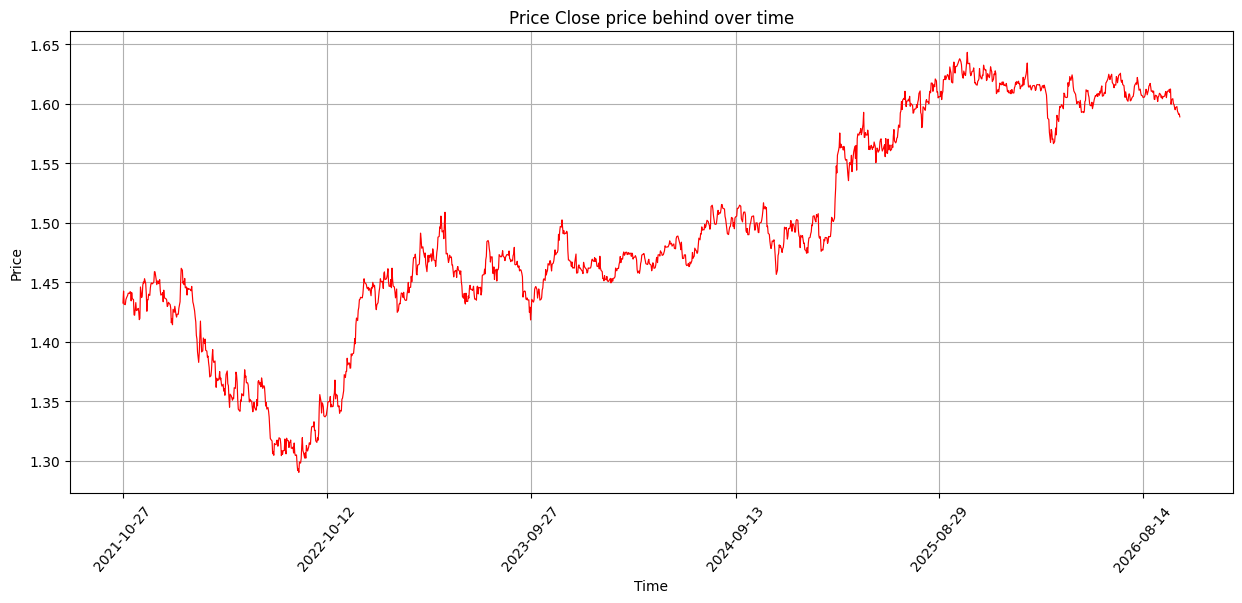

In [242]:
plot_lines_graph_forex(eurcad)

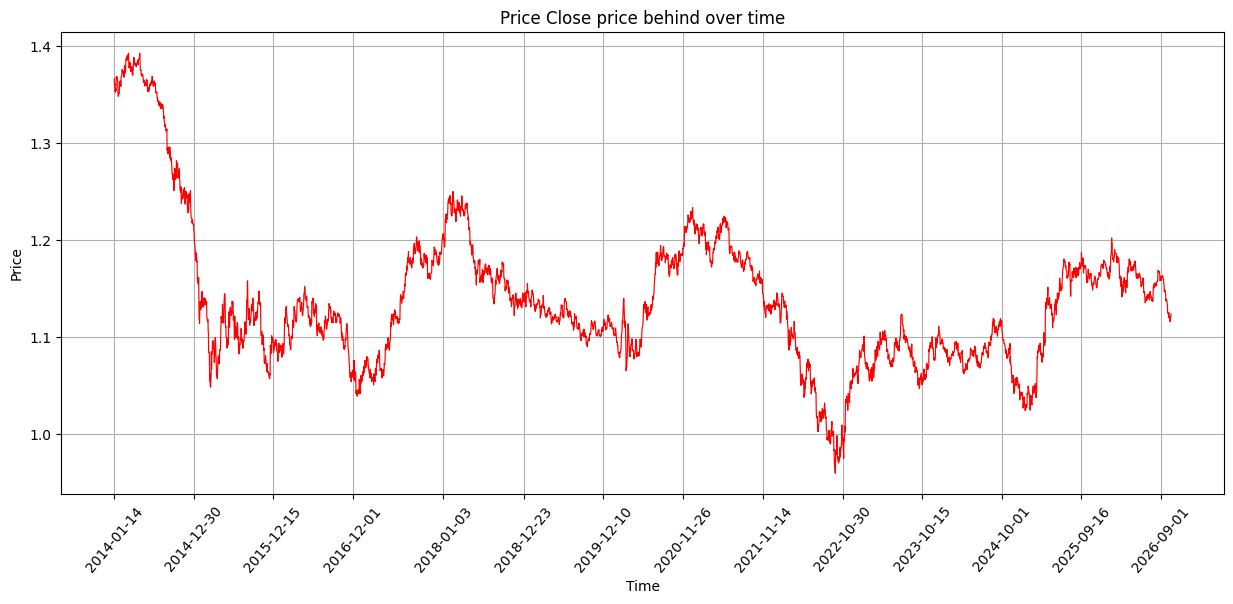

In [243]:
plot_lines_graph_forex(eurusd)

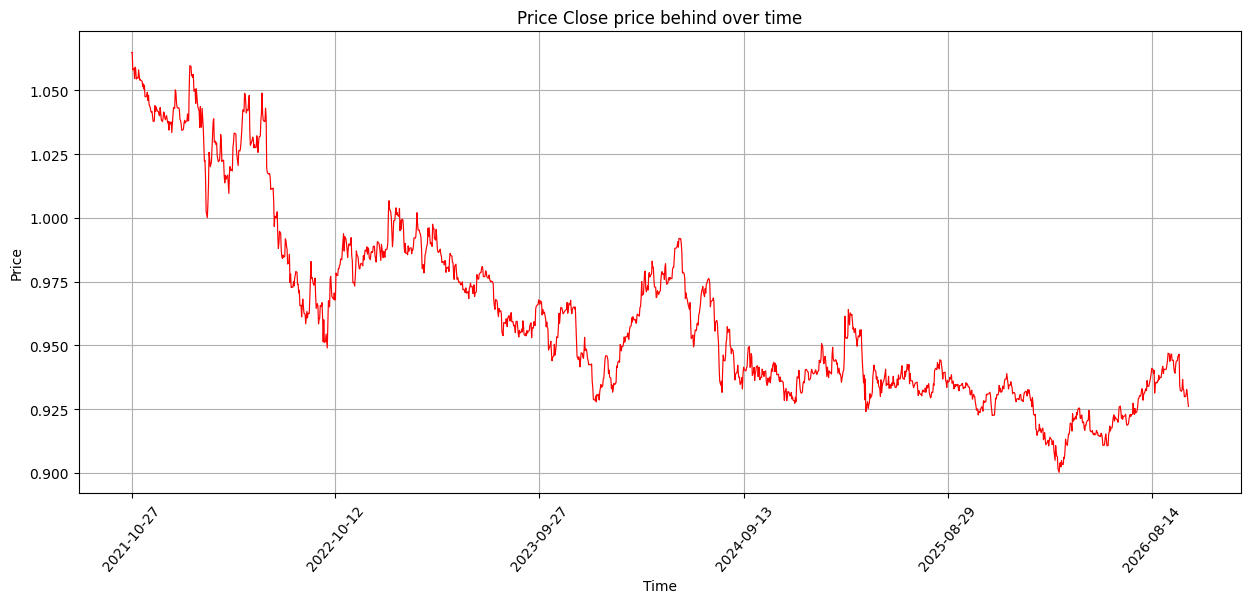

In [244]:
plot_lines_graph_forex(eurchf)

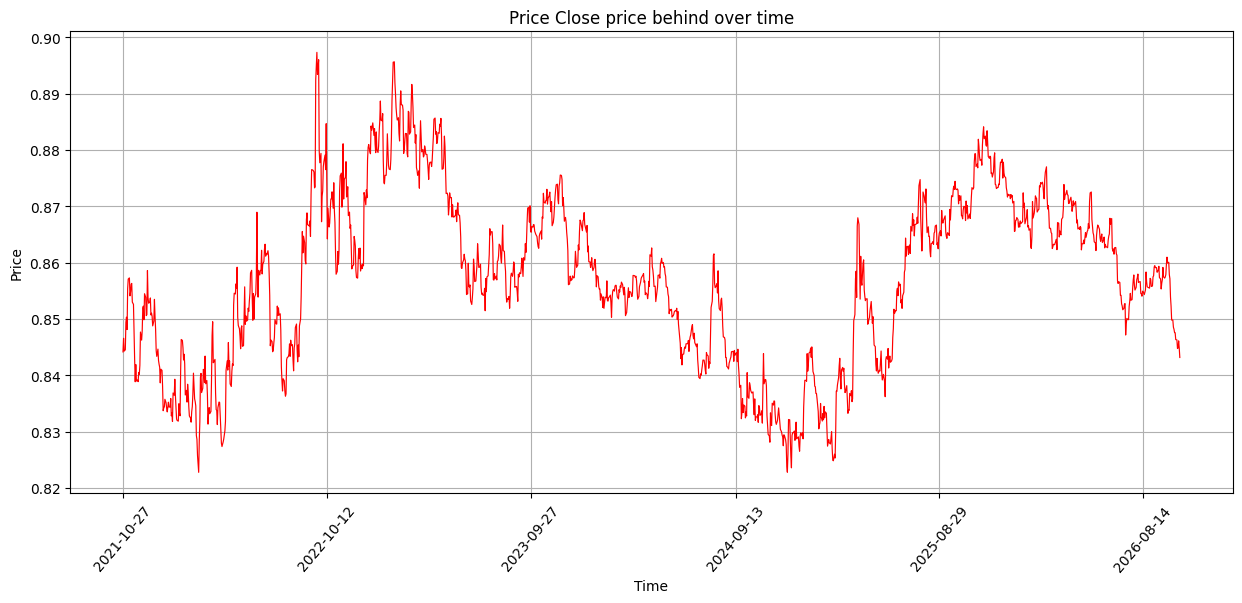

In [245]:
plot_lines_graph_forex(eurgbp)

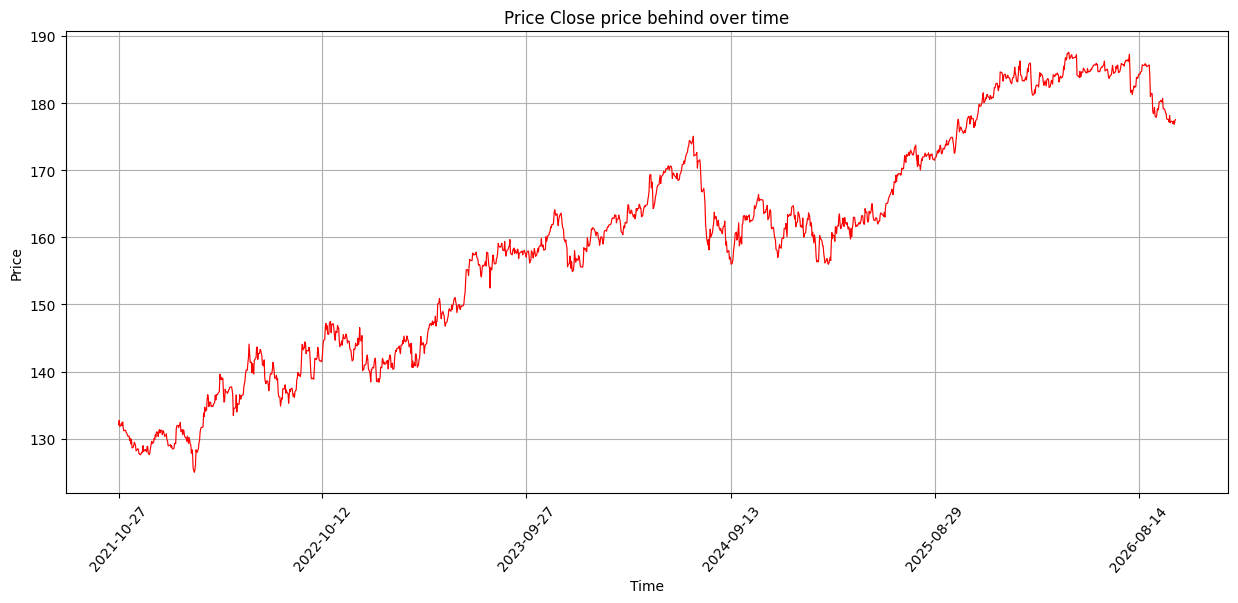

In [246]:
plot_lines_graph_forex(eurjpy)

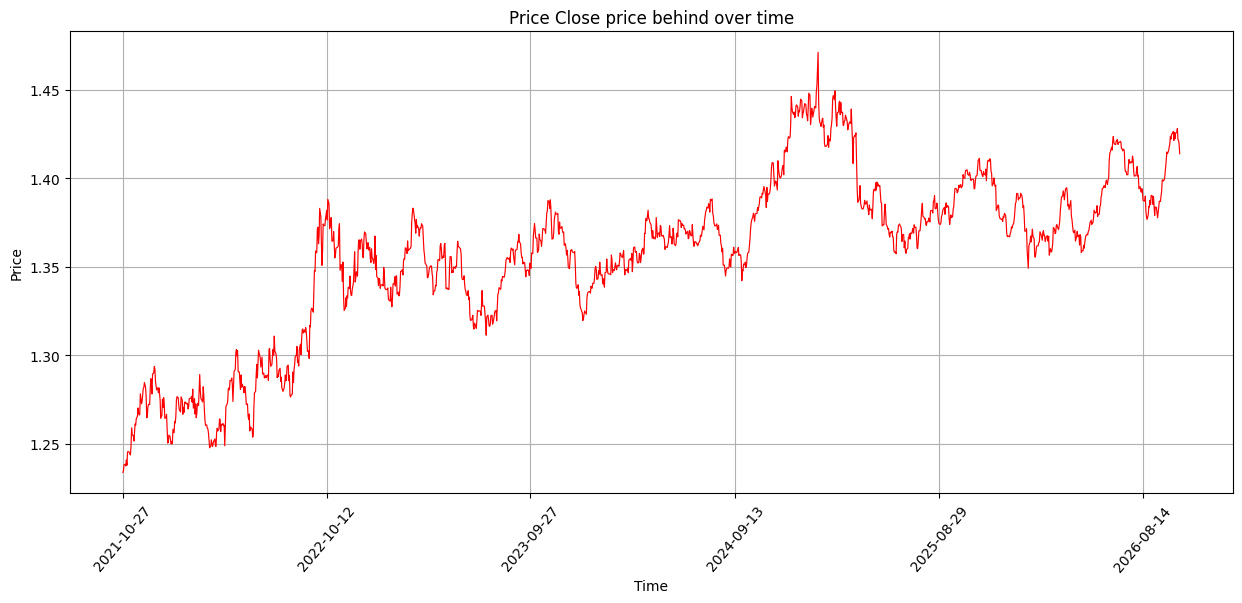

In [247]:
plot_lines_graph_forex(usdcad)

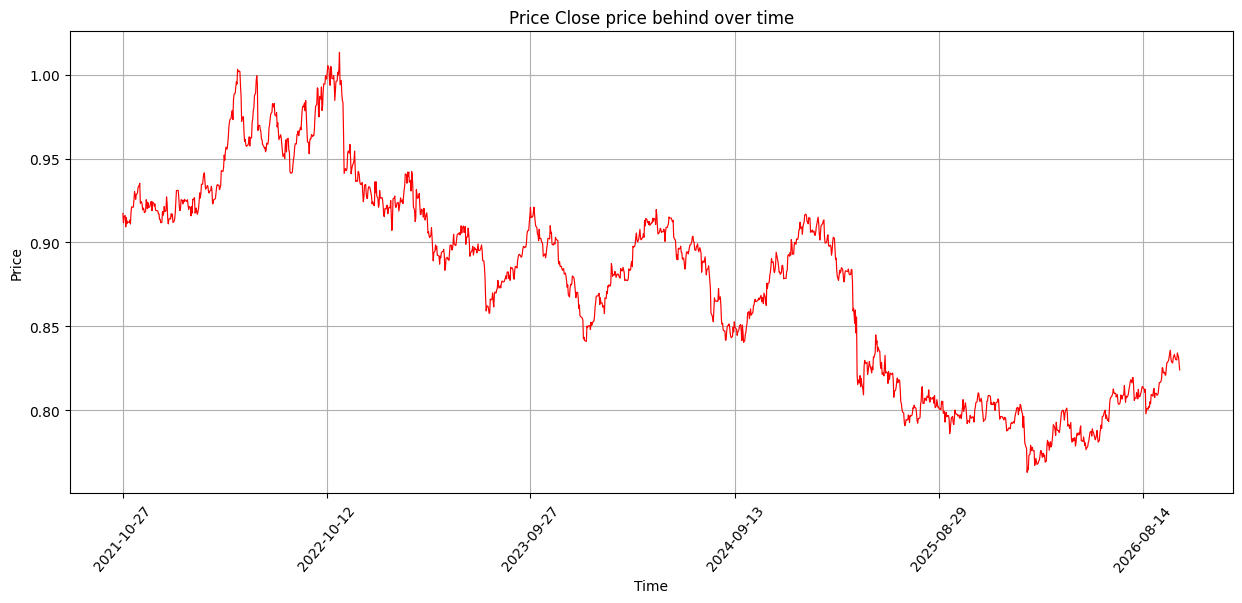

In [248]:
plot_lines_graph_forex(usdchf)

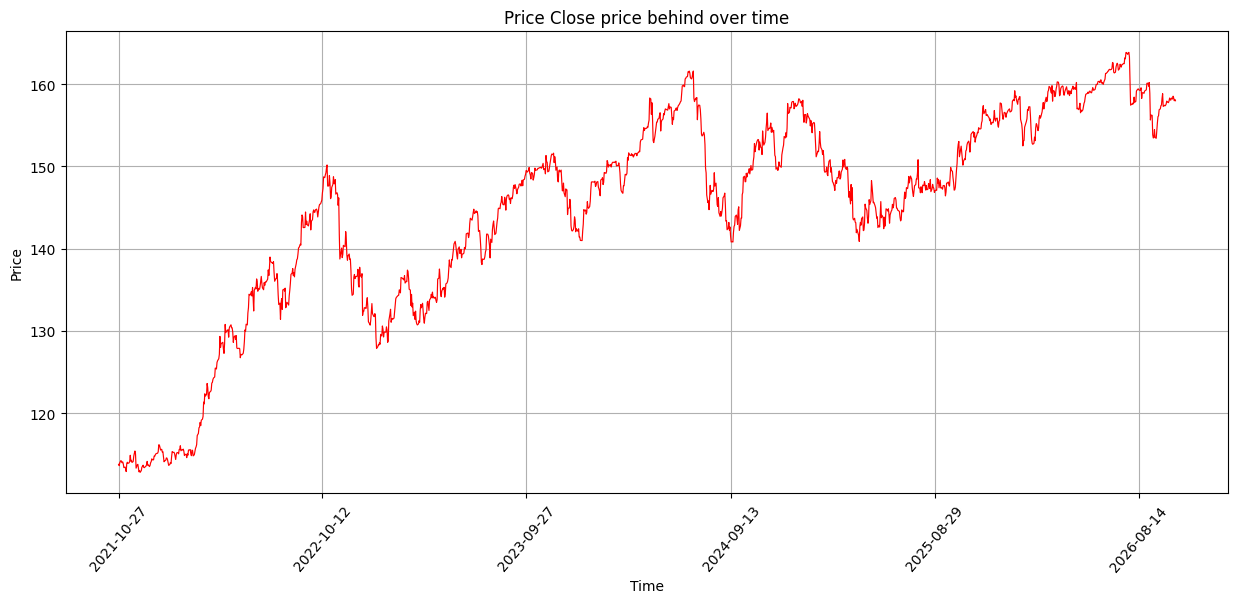

In [249]:
plot_lines_graph_forex(usdjpy)

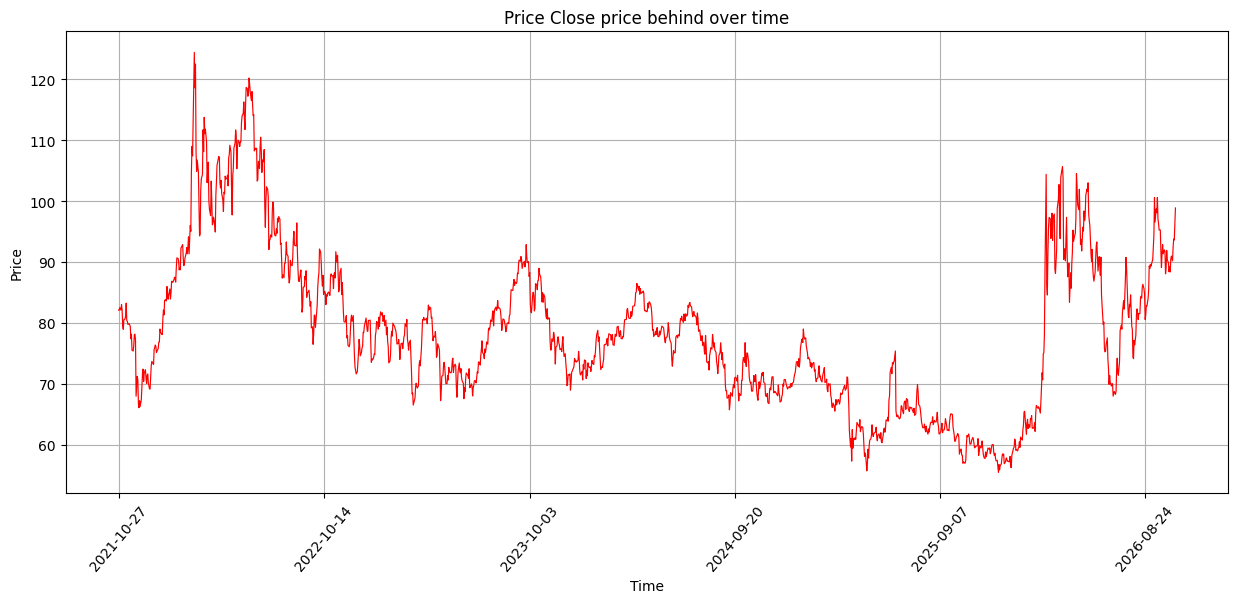

In [250]:
plot_lines_graph_forex(wti)

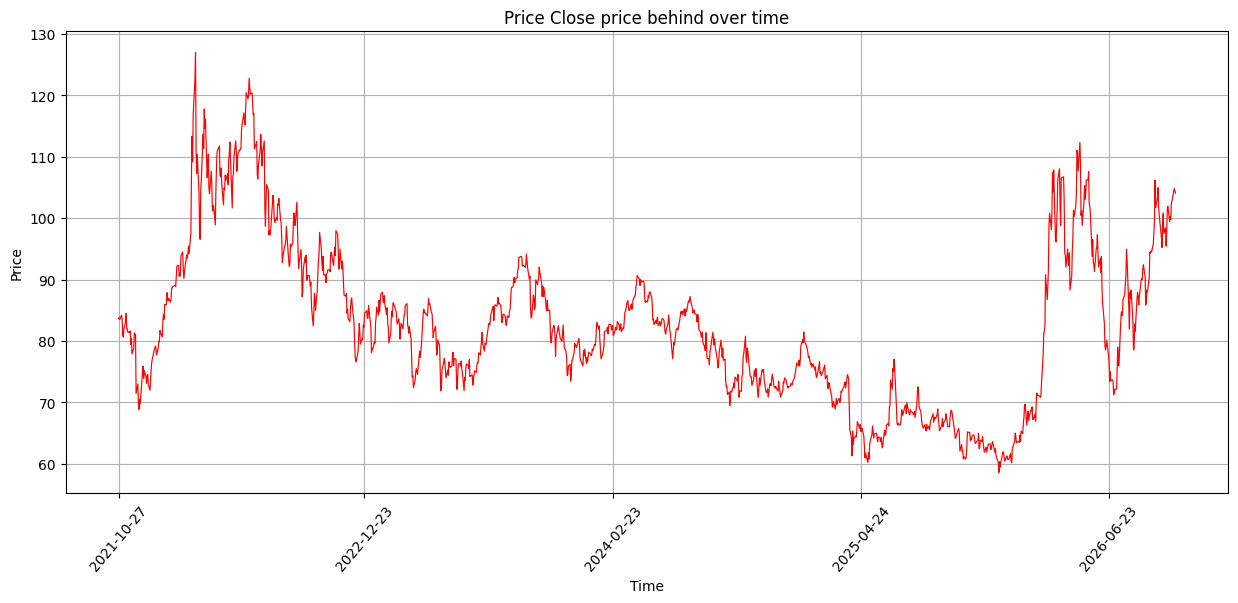

In [251]:
plot_lines_graph_forex(brent)

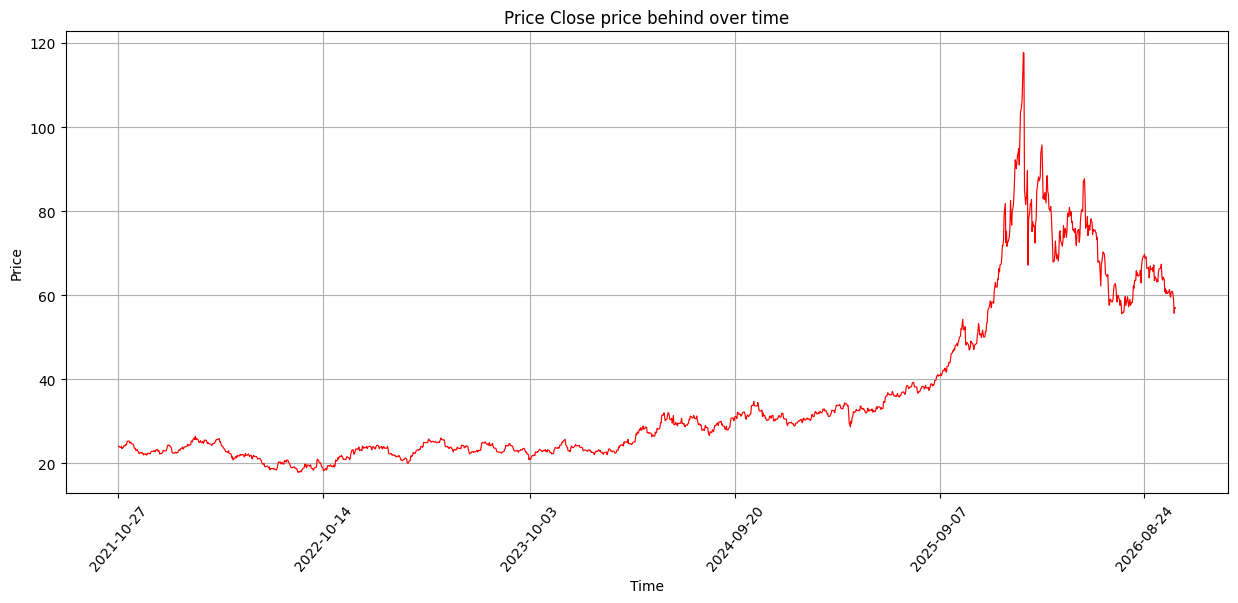

In [252]:
plot_lines_graph_forex(silver)

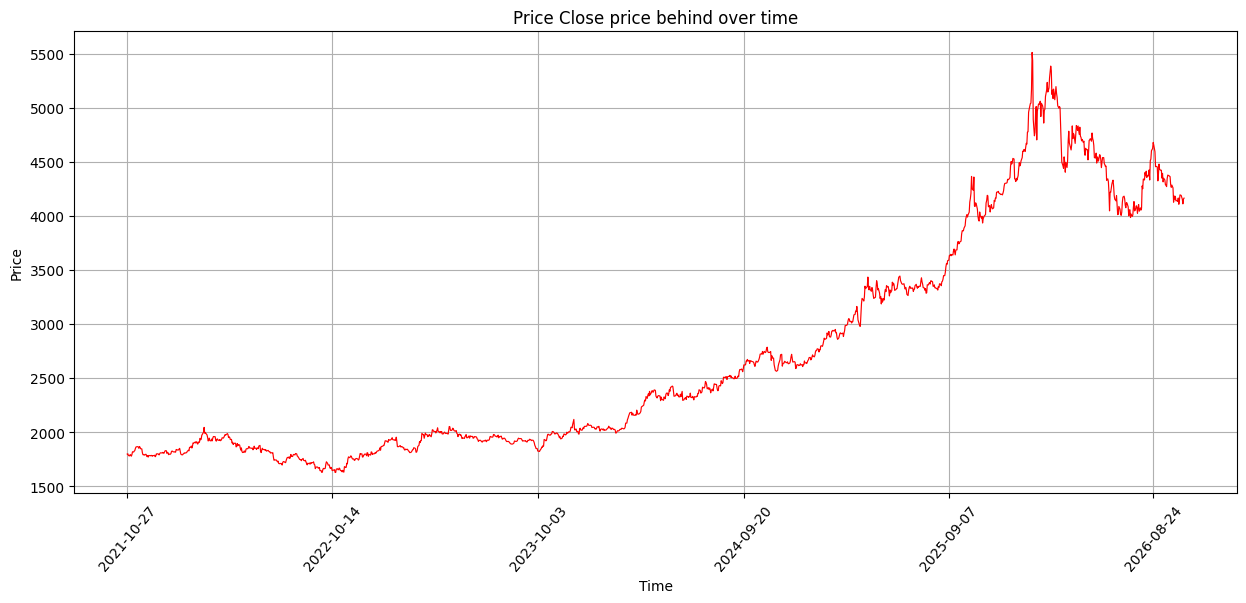

In [253]:
plot_lines_graph_forex(gold)

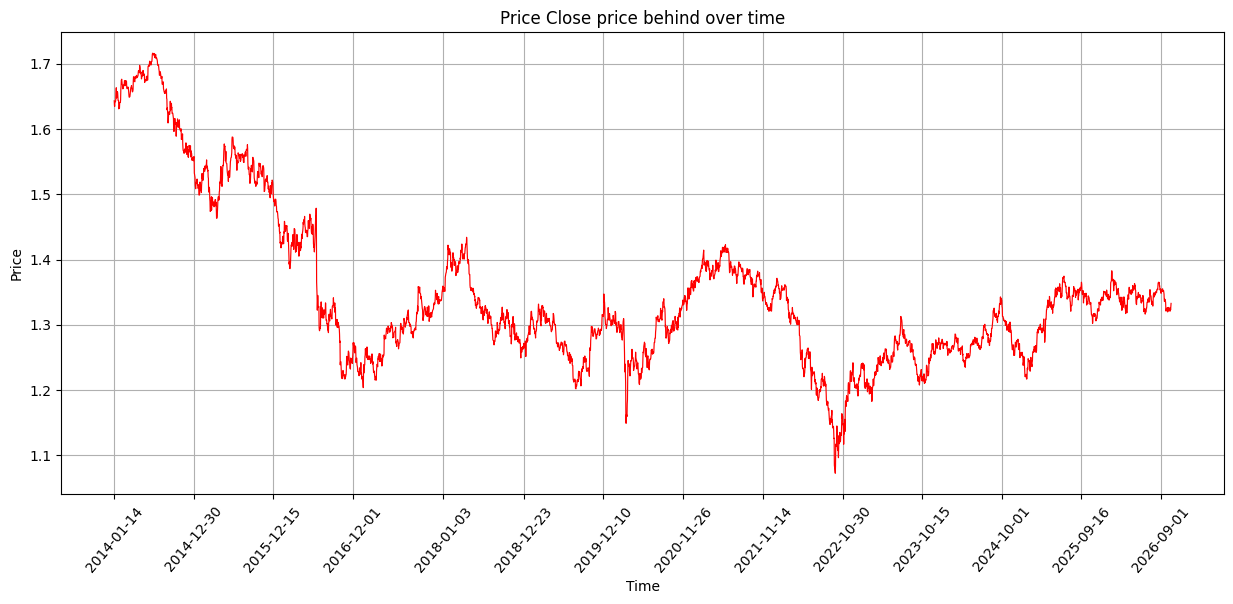

In [254]:
plot_lines_graph_forex(gbpusd)

In [268]:
def plot_lines_graph_macro(df):

    plt.plot(df.reference_date, df.inflation_yoy, linewidth=0.85, color='green', label='Inflation')
    plt.plot(df.reference_date, df.central_bank_rate, linewidth=0.85, color='blue', label='Interest')
    plt.plot(df.reference_date, df.real_gdp_growth_qoq, linewidth=0.85, color='red', label='PIB')
    plt.xlabel('Time')
    plt.ylabel('Value')
    ax = plt.gca()
    ax.set_xticks(df.reference_date[::50])
    plt.xticks(rotation=50)
    plt.title('Macro indicators values')
    plt.legend()
    plt.grid(True)
    plt.show()

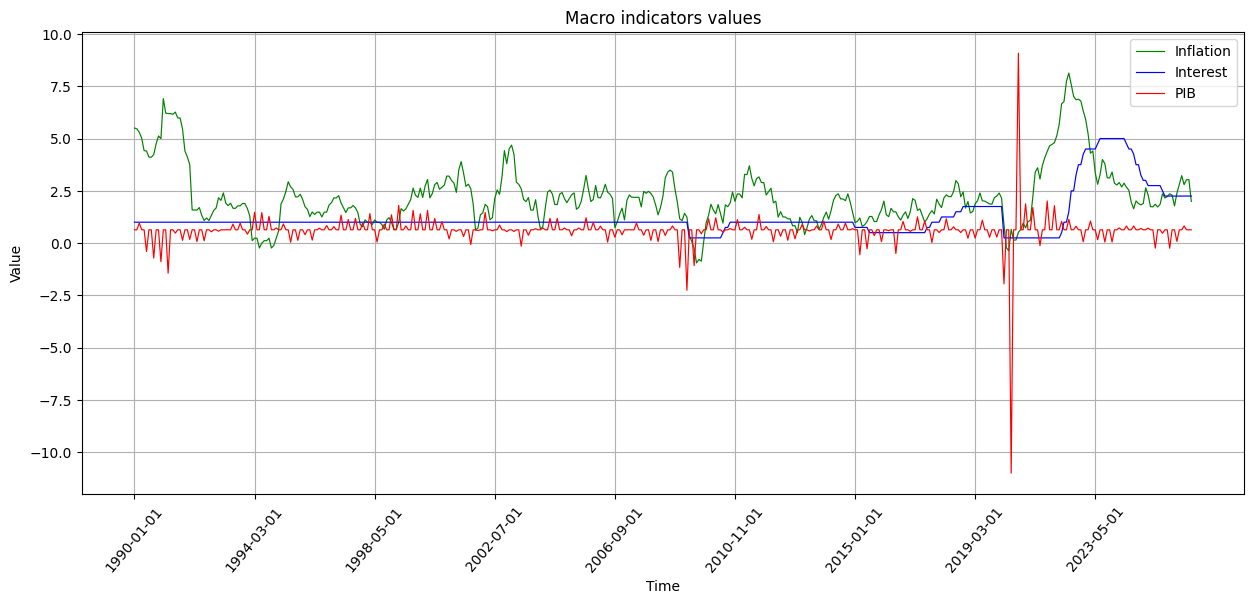

In [269]:
plot_lines_graph_macro(canada)

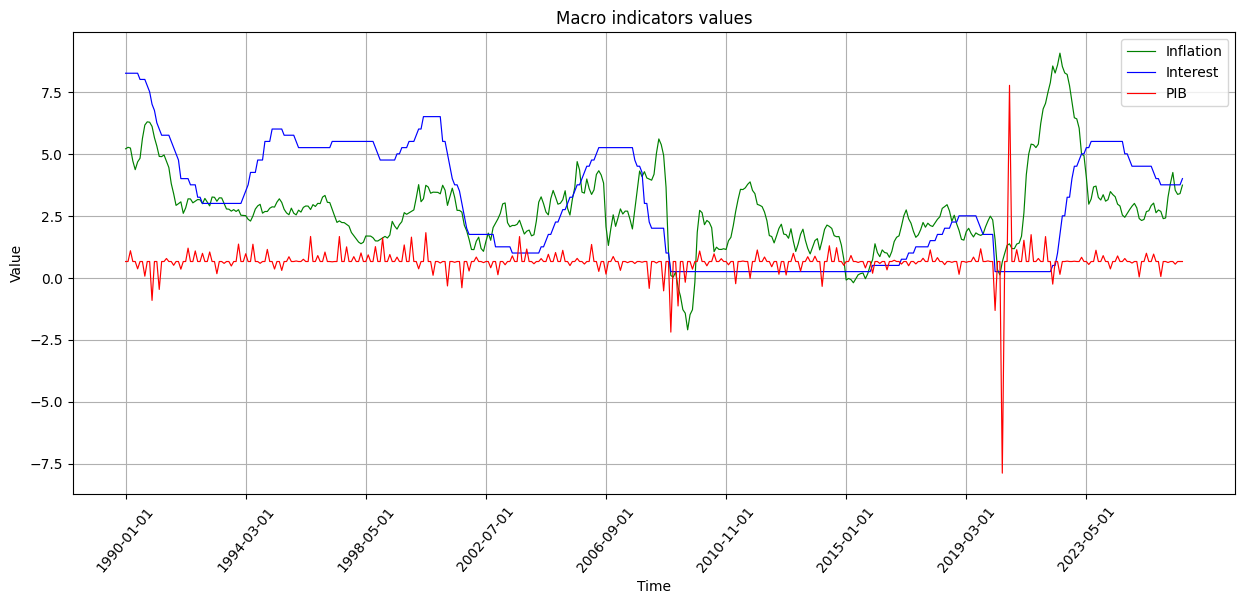

In [270]:
plot_lines_graph_macro(usa)

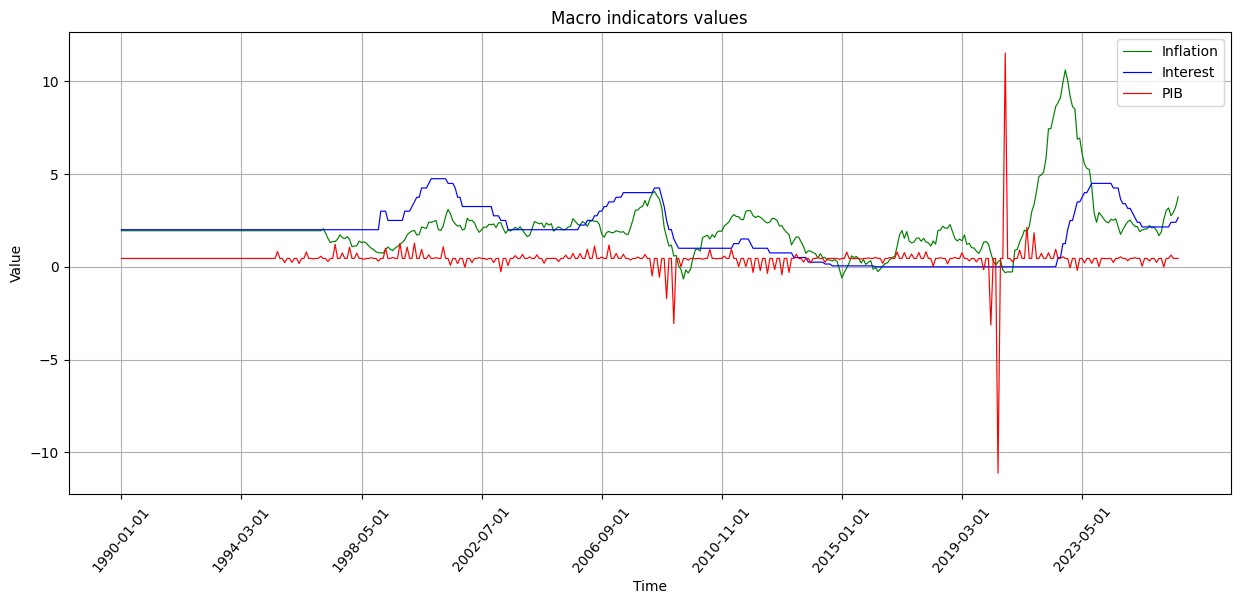

In [271]:
plot_lines_graph_macro(euro_zone)

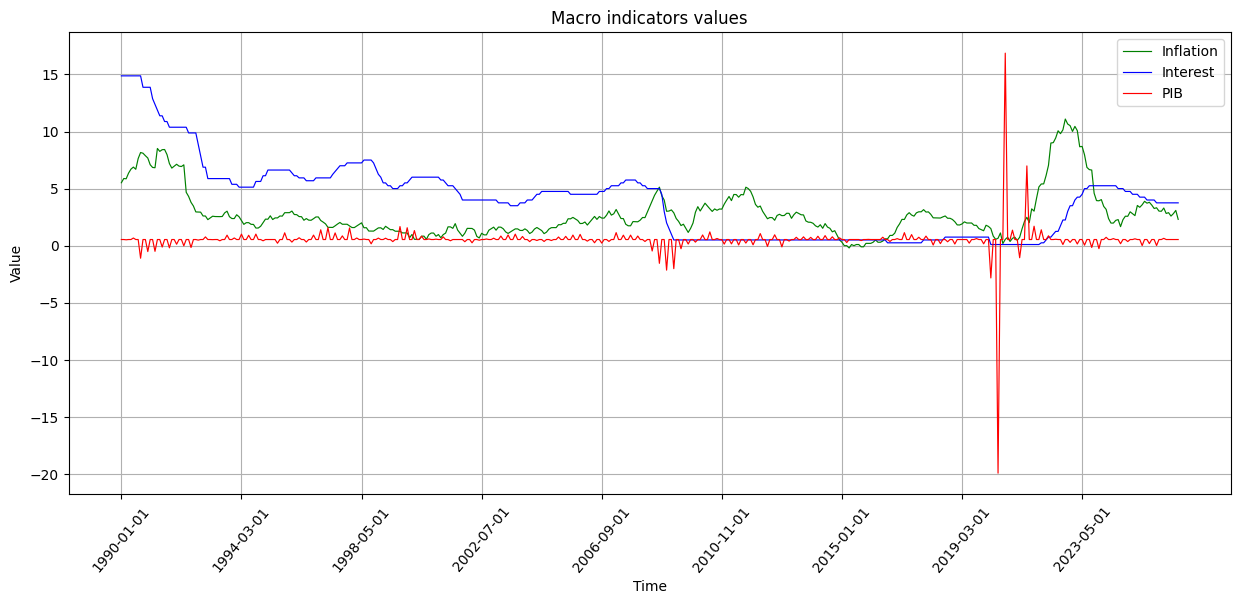

In [272]:
plot_lines_graph_macro(england)

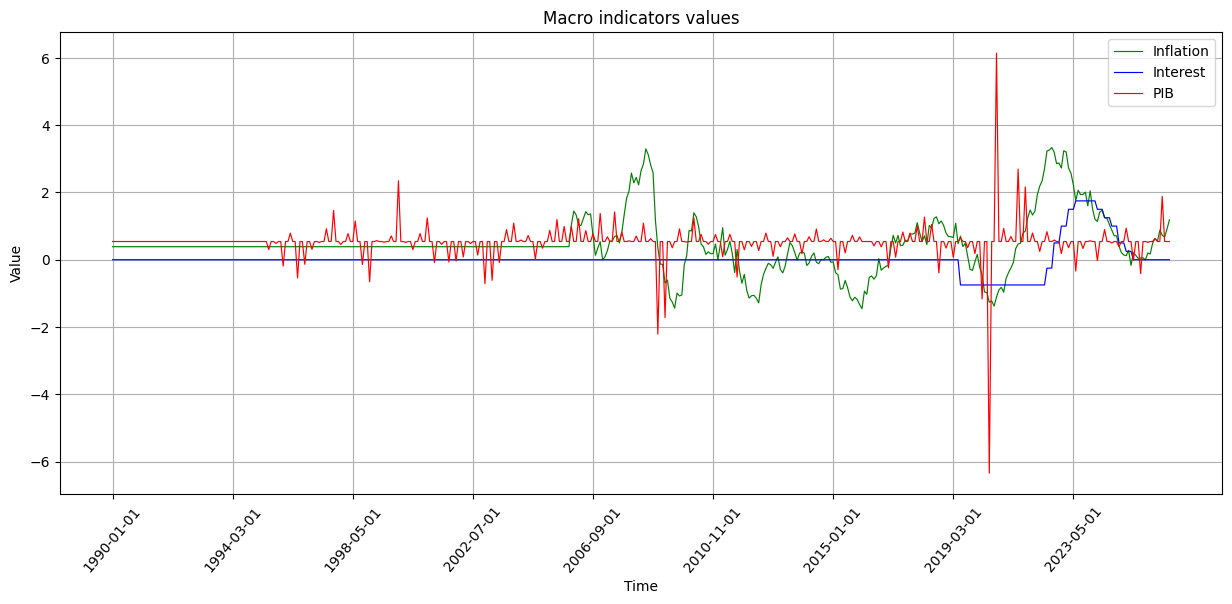

In [273]:
plot_lines_graph_macro(switz)

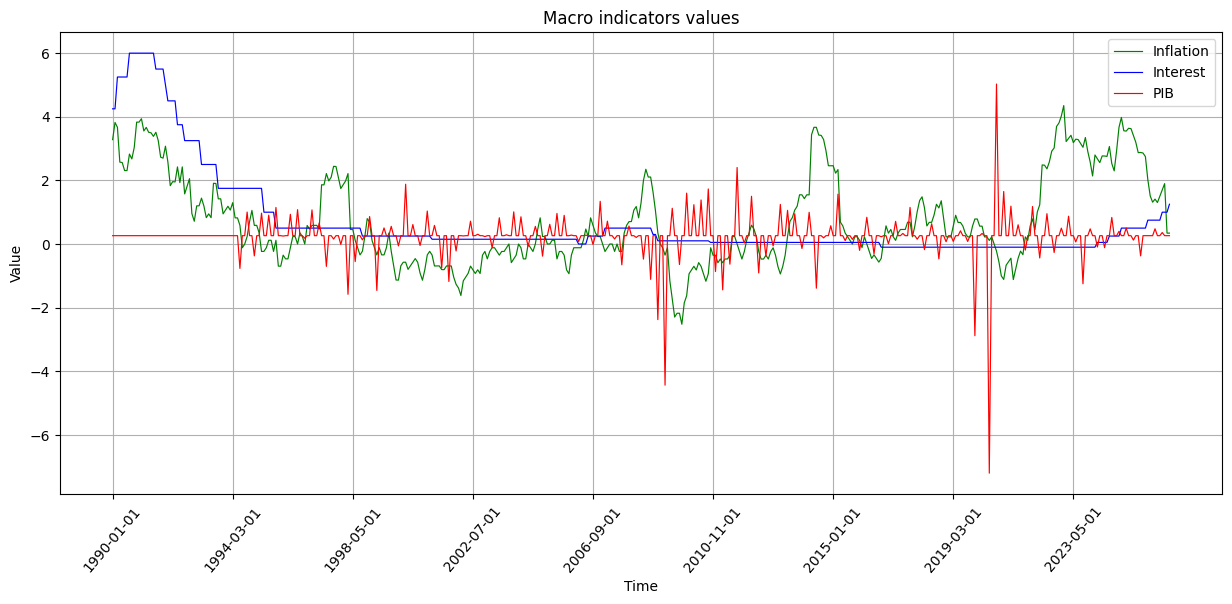

In [274]:
plot_lines_graph_macro(japan)